# 01 — Exploratory Data Analysis (EDA)

**Tugas:** klasifikasi halaman dokumen hasil scan ke dalam 16 kelas. Dataset kompetisi berisi metadata gambar dan label; metriknya adalah accuracy multikelas. Notebook ini memeriksa struktur data, distribusi kelas, contoh halaman, dan kualitas data sebelum pemodelan.

Jalankan notebook dari repository setelah mengunduh dan mengekstrak data sesuai README. Label test tidak tersedia dan tidak digunakan dalam pemilihan model.

In [1]:
from pathlib import Path
import sys

# Notebook dapat dijalankan dari root repository atau folder notebooks/.
ROOT = Path.cwd().resolve()
if not (ROOT / "pyproject.toml").is_file():
    ROOT = ROOT.parent
if not (ROOT / "pyproject.toml").is_file():
    raise FileNotFoundError("Jalankan notebook dari root repository atau folder notebooks/.")
DATA_DIR = ROOT / "data"
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

## 1. Membaca metadata

`train.csv` berisi `id`, `filename`, `class_name`, dan `label`; `test.csv` berisi `id` dan `filename`. Nama file pada metadata relatif terhadap folder data. Pada arsip ini gambar diekstrak ke `train/train/` dan `test/test/`.

In [2]:
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
print("Train:", train.shape, "Test:", test.shape)
display(train.head())
display(test.head())

Train: (32003, 4) Test: (7994, 2)


,id,filename,class_name,label
0,train_00001,train/resume/50497291-7292.tif,resume,12
1,train_00002,train/scientific_publication/50728670-8670.tif,scientific_publication,13
2,train_00003,train/scientific_report/87112192.tif,scientific_report,14
3,train_00004,train/scientific_publication/10343650_10343655...,scientific_publication,13
4,train_00005,train/specification/2057960699_2057960701.tif,specification,15


,id,filename
0,test_00001,test/test_00001.tif
1,test_00002,test/test_00002.tif
2,test_00003,test/test_00003.tif
3,test_00004,test/test_00004.tif
4,test_00005,test/test_00005.tif


In [3]:
print("Nilai kosong train:", train.isna().sum().to_dict())
print("Nilai kosong test:", test.isna().sum().to_dict())
print("Duplikat ID train/test:", train.id.duplicated().sum(), test.id.duplicated().sum())
assert set(train.columns) == {"id", "filename", "class_name", "label"}
assert set(test.columns) == {"id", "filename"}
assert train.id.is_unique and test.id.is_unique
assert train.label.between(0, 15).all()

Nilai kosong train: {'id': 0, 'filename': 0, 'class_name': 0, 'label': 0}
Nilai kosong test: {'id': 0, 'filename': 0}
Duplikat ID train/test: 0 0


## 2. Distribusi kelas

Pemeriksaan ini menggunakan seluruh metadata training, bukan label test. Perbedaan jumlah sampel antar kelas perlu diperhatikan saat membuat split.

,label,class_name,jumlah
0,0,advertisement,2012
1,1,budget,2004
2,2,email,2013
3,3,file_folder,2022
4,4,form,2005
5,5,handwritten,2026
6,6,invoice,1982
7,7,letter,1972
8,8,memo,1994
9,9,news_article,1971


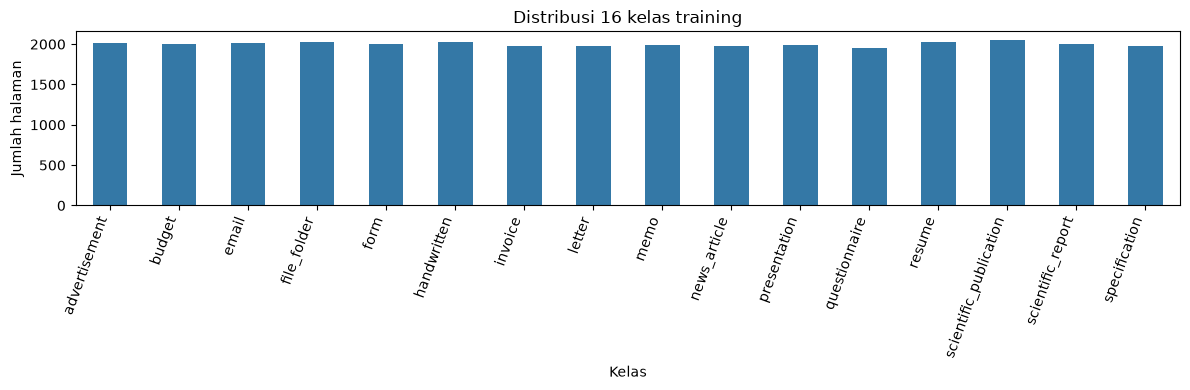

Kelas terkecil/terbesar: 1948 / 2056


In [4]:
distribution = (train.groupby(["label", "class_name"]).size()
                .rename("jumlah").reset_index().sort_values("label"))
display(distribution)
ax = distribution.plot.bar(x="class_name", y="jumlah", legend=False, figsize=(12, 4), color="#3478a6")
ax.set(title="Distribusi 16 kelas training", xlabel="Kelas", ylabel="Jumlah halaman")
plt.xticks(rotation=70, ha="right")
plt.tight_layout()
plt.show()
print("Kelas terkecil/terbesar:", distribution.jumlah.min(), "/", distribution.jumlah.max())

## 3. Contoh halaman dan resolusi

Citra dibuka dalam mode aslinya untuk melihat variasi halaman. Saat training, pipeline mengonversi citra menjadi RGB dan mengubah ukuran menjadi 224 × 224 piksel.

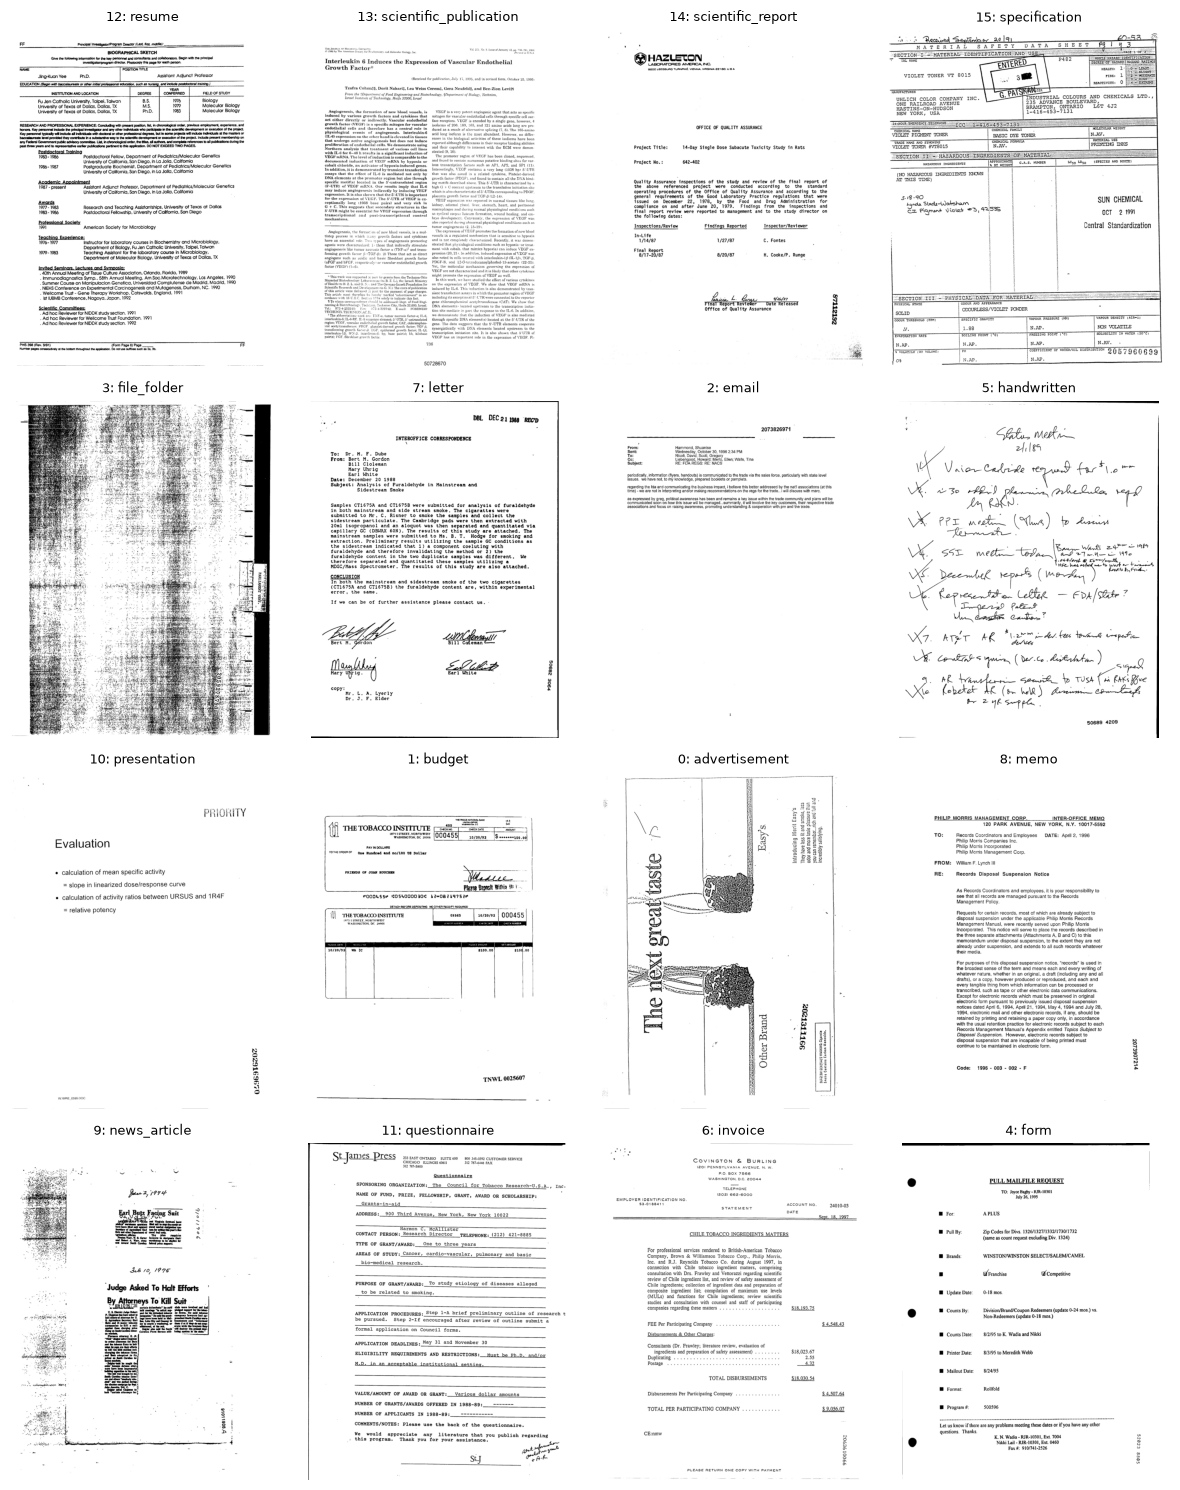

In [5]:
def image_path(filename):
    """Temukan file dari metadata pada layout arsip lokal atau layout datar."""
    relative = Path(filename)
    candidates = [DATA_DIR / relative, DATA_DIR / relative.parts[0] / relative]
    return next((path for path in candidates if path.is_file()), candidates[0])

samples = train.sort_values("id").groupby("label", sort=True).head(1)
fig, axes = plt.subplots(4, 4, figsize=(12, 15))
for ax, (_, row) in zip(axes.flat, samples.iterrows()):
    with Image.open(image_path(row.filename)) as page:
        ax.imshow(page.convert("RGB"))
        ax.set_title(f"{row.label}: {row.class_name}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [6]:
properties = []
for _, row in train.head(32).iterrows():
    with Image.open(image_path(row.filename)) as page:
        properties.append({"id": row.id, "width": page.width, "height": page.height, "mode": page.mode})
image_properties = pd.DataFrame(properties)
display(image_properties.head())
display(image_properties[["width", "height"]].describe())
print("Mode pada 32 contoh:", image_properties['mode'].value_counts().to_dict())

,id,width,height,mode
0,train_00001,754,1000,L
1,train_00002,754,1000,L
2,train_00003,779,1000,L
3,train_00004,772,1000,L
4,train_00005,845,1000,L


,width,height
count,32.000000,32.0
mean,772.781250,1000.0
std,26.563053,0.0
min,754.000000,1000.0
25%,754.000000,1000.0
50%,764.000000,1000.0
75%,777.000000,1000.0
max,872.000000,1000.0


Mode pada 32 contoh: {'L': 32}


## 4. Temuan dan penanganan

- Pada data yang diperiksa terdapat 32.003 baris train dan 7.994 baris test; jalankan sel di atas untuk memverifikasi data lokal.
- Distribusi training relatif seimbang (1.948–2.056 halaman per kelas). Split train/validation dibuat stratified pada notebook berikutnya.
- Run DiT-large mencatat satu gambar train yang tidak dapat didekode, `train_08795`. Dataset mengembalikan penanda untuk melewati gambar tersebut; seluruh 6.401 gambar validation pada run tersebut dapat digunakan.
- Metadata EXIF yang rusak dapat menghasilkan peringatan PIL; peringatan itu berbeda dari gambar yang gagal dibaca. Rincian run ada pada `reports/experiments/dit_large_v2/`.